# F_basic_ephys.ipynb

## Purpose
Characterizes electrophysiological unit properties for opto-tagged and untagged neurons. Generates quality-control metric distributions and the go-cue excitation vs. baseline correlation scatter plot.

## Prerequisites
- `basic_ephys.pkl` — basic ephys metrics per unit (`manuscript_fig_prep_dir/basic_ephys/`)
- `acf_fit_parameters_with_pcs.csv` — ACG fit parameters with PCs (`manuscript_fig_prep_dir/acg/`)
- `acf_fit_parameters_and_components.pkl` — ACG fit parameters and components (`manuscript_fig_prep_dir/acg/`)
- `combined_unit_tbl.pkl` — quality-controlled unit table (`manuscript_fig_prep_dir/combined_unit_tbl/`)
- `combined_antidromic_results.pkl` — antidromic classification results (`manuscript_fig_prep_dir/antidromic_analysis/PrL_S1/`)
- `basic_ephys_all.json` — QC criteria (`code/beh_ephys_analysis/session_combine/metrics/`)
- `model_combined_beh_all.csv` — behavioral regression model results per unit (`manuscript_fig_prep_dir/outcome_regressions/`)
- `response_ratio_beh_all_go_cue.csv` — go-cue response ratio per unit (`manuscript_fig_prep_dir/response_regression/`)
- `combined_features.csv` — waveform features (`manuscript_fig_prep_dir/waveforms_np/`)

## Figure Panels
- **Figure4h**: Go-cue excitation versus go-baseline correlation (scatter)
- **FigureE10e**: Single-unit quality metrics for identified and unidentified neurons (scatter + marginal distributions)
- **FigureE10f_topleft**: ISI violation ratio for identified and unidentified neurons (histogram)
- **FigureE10f_topright**: Waveform peak for identified and unidentified neurons (histogram)
- **FigureE10f_bottomleft**: Euclidean distance between waveforms of spontaneous and evoked spikes (histogram)
- **FigureE10f_bottomright**: Correlation between waveforms of spontaneous and evoked spikes (histogram)

## Imports and Path Setup

Import all required libraries and resolve the `beh_ephys_analysis` root so that `utils` sub-modules are importable regardless of execution environment.

In [3]:
import os

# Resolve code/beh_ephys_analysis (the folder containing `utils`) relative to this
# file's location, so imports work no matter where the repo is checked out.
import pathlib
import sys

# Resolve code/beh_ephys_analysis (the folder containing `utils`) relative to this
# file's location, so imports work no matter where the repo is checked out.
try:
    _here = pathlib.Path(__file__).resolve().parent          # script mode
except NameError:
    try:
        _here = pathlib.Path(__vsc_ipynb_file__).resolve().parent  # VS Code notebook
    except NameError:
        _here = pathlib.Path(os.getcwd())                    # other Jupyter fallback

_beh_ephys_root = str((_here / '../..').resolve())
if _beh_ephys_root not in sys.path:
    sys.path.insert(0, _beh_ephys_root)
import json
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from utils.beh_functions import (
    parseSessionID,
)
from utils.capsule_migration import capsule_directories
from utils.combine_tools import (
    apply_qc,
    to_str_intlike,
)
from utils.ephys_functions import *

warnings.filterwarnings('ignore')
capsule_dirs = capsule_directories()

%matplotlib inline
from utils.capsule_migration import CAPSULE_ROOT
from utils.panel_utils import columns_to_df, save_panel_csv, save_panels


## Data Loading

Load basic ephys metrics (`basic_ephys.pkl`), ACG fit parameters, the combined unit table with opto-tagging and antidromic stimulation results, and apply the `basic_ephys_all` QC criteria JSON to classify units.

In [4]:
# load basic ephys
target_folder = f'{capsule_dirs["manuscript_fig_dir"]}/F_basic_ephys'
if not os.path.exists(target_folder):
    os.makedirs(target_folder)
be_folder = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'basic_ephys')
be_file = os.path.join(be_folder, f'basic_ephys.pkl')
with open(be_file, 'rb') as f:
    basic_ephys_df = pickle.load(f)
filter = basic_ephys_df['be_filter'].values
filter = np.array(filter, dtype=bool)
basic_ephys_df['be_filter'] = filter
basic_ephys_df.rename(columns={'unit': 'unit_id'}, inplace=True)
basic_ephys_df['unit_id'] = basic_ephys_df['unit_id'].apply(to_str_intlike)

In [5]:
# # load parameters for acg
# fit_params_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'acg', 'acf_fit_parameters_with_pcs.csv')
# fit_params_df = pd.read_csv(fit_params_file)
# fit_params_mat_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'acg', 'acf_fit_parameters_and_components.pkl')
# with open(fit_params_mat_file, 'rb') as f:
#     fit_data = pickle.load(f)
# C1_mat = fit_data['C1_mat']
# C2_mat = fit_data['C2_mat']
# C3_mat = fit_data['C3_mat']
# auto_corr = fit_data['acg_mat']
# # add_auto_corr to df
# fit_params_df['C1'] = C1_mat.tolist()  # convert numpy array to list for storage in DataFrame
# fit_params_df['C2'] = C2_mat.tolist()  # convert numpy array to list for storage in DataFrame
# fit_params_df['C3'] = C3_mat.tolist()  # convert numpy array to list for storage in DataFrame
# fit_params_df['auto_corr'] = auto_corr.tolist()  # convert numpy array to list for storage in DataFrame

In [6]:
with open(os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'combined_unit_tbl', 'combined_unit_tbl.pkl'), 'rb') as f:
    combined_tagged_units = pickle.load(f)
combined_tagged_units.rename(columns={'unit': 'unit_id'}, inplace=True)
# exlcude units from excluded sessions
combined_tagged_units['unit_id'] = combined_tagged_units['unit_id'].apply(to_str_intlike)
# antidromic data
# version = 'PrL_S1'
# antidromic_file = f'{capsule_dirs["manuscript_fig_prep_dir"]}/antidromic_analysis/{version}/combined_antidromic_results.pkl'
# with open(antidromic_file, 'rb') as f:
#     antidromic_df = pickle.load(f)

# antidromic_df.rename(columns={'unit': 'unit_id'}, inplace=True)
# antidromic_df['unit_id'] = antidromic_df['unit_id'].apply(to_str_intlike)
# antidromic_df = antidromic_df[['unit_id', 'session', 'p_auto_inhi', 't_auto_inhi',
#        'p_collision', 't_collision', 'p_antidromic', 't_antidromic', 'tier_1',
#        'tier_2', 'tier_1_long', 'tier_2_long']].copy()
# combined_tagged_units = combined_tagged_units.merge(antidromic_df, on=['session', 'unit_id'], how='left')
# combined_tagged_units['tier_1'] = combined_tagged_units['tier_1'].fillna(False)
# combined_tagged_units['tier_2'] = combined_tagged_units['tier_2'].fillna(False)
# combined_tagged_units['tier_1_long'] = combined_tagged_units['tier_1_long'].fillna(False)
# combined_tagged_units['tier_2_long'] = combined_tagged_units['tier_2_long'].fillna(False)


## Quality Control: Apply Filters and Visualize Metrics

Apply the `basic_ephys_all` QC constraints to produce a filtered set of high-quality opto-tagged units, and save a summary figure of the unit quality metrics distribution.

Applying bounds for isi_violations: [0, 0.1]
 - isi_violations: 15278 -> 6733 units passed
Applying items for in_LC: [True]
 - in_LC: 6733 -> 1252 units passed
Applying items for qc_pass: [True]
 - qc_pass: 1252 -> 948 units passed
Applying bounds for peak: [-1000, 500]
 - peak: 948 -> 947 units passed
 - sd: 947 -> 947 units passed
Applying conditional bounds for y_loc
 - y_loc: 947 -> 946 units passed
Applying opto conditions: ['p_max', 'eu', 'corr', 'tag_loc', 'lat_max_p', 'p_mean', 'sig_counts']
Number of opto rows after filtering: 154
Number of non-opto rows after filtering: 946


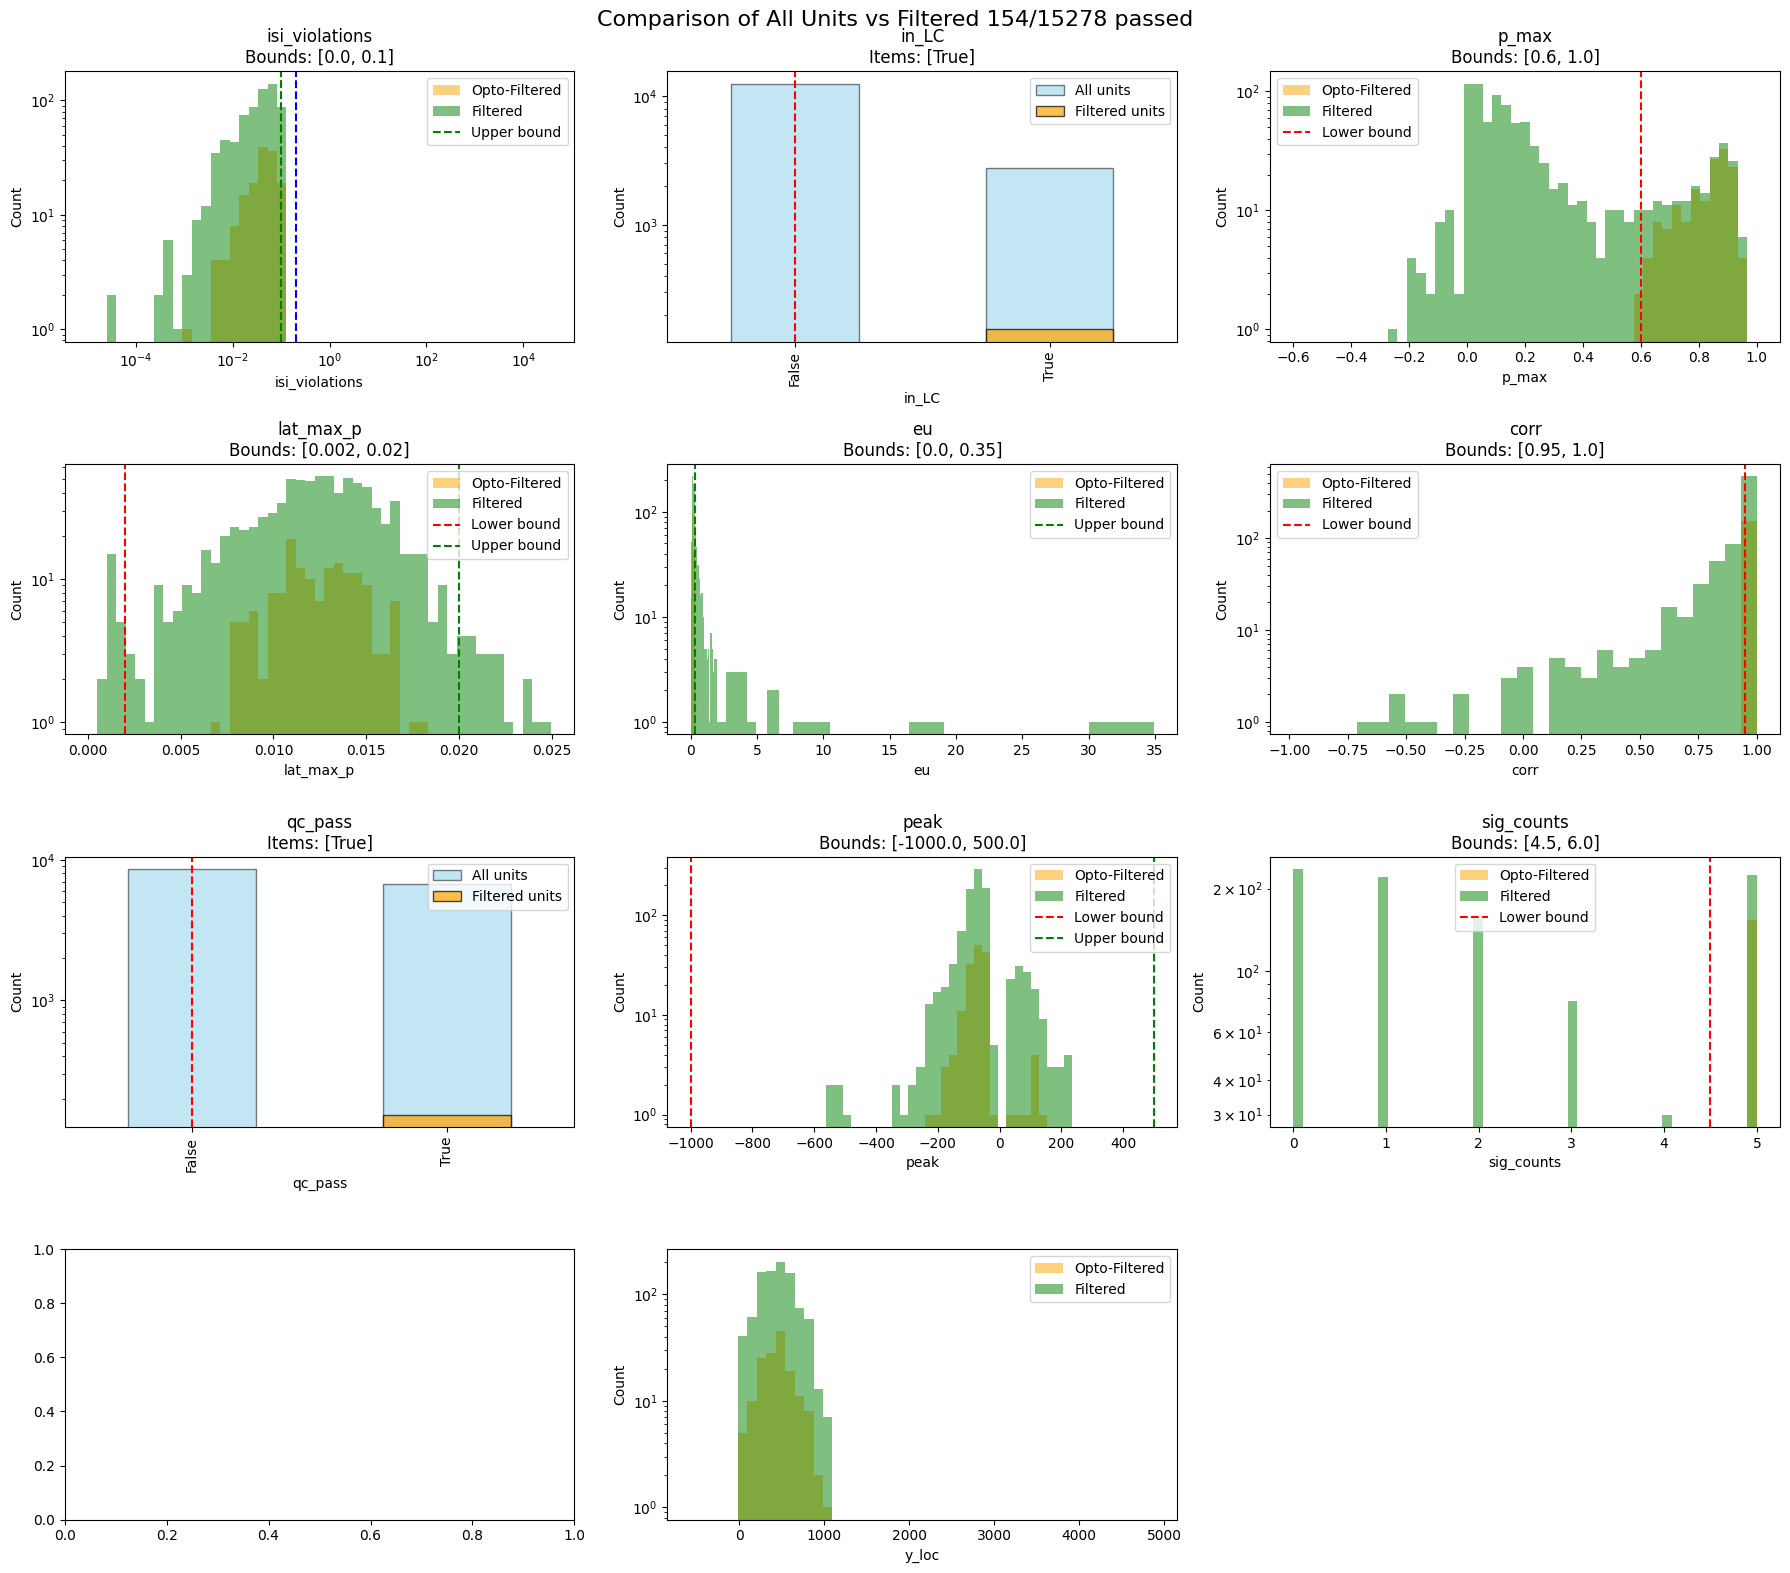

In [7]:
density = False
criteria_name = 'basic_ephys_all_LC'
with open(os.path.join(CAPSULE_ROOT + '/code/beh_ephys_analysis/session_combine/metrics', f'{criteria_name}.json'), 'r') as f:
    constraints = json.load(f)
constraints['sd'] = [0, 1]
combined_tagged_units_filtered, combined_tagged_units, fig, axes = apply_qc(combined_tagged_units, constraints, density=density, plot_all=False, plot_half=True)
combined_tagged_units.rename(columns={'unit': 'unit_id'}, inplace=True)
combined_tagged_units['unit_id'] = combined_tagged_units['unit_id'].apply(to_str_intlike)
combined_tagged_units_filtered.rename(columns={'unit': 'unit_id'}, inplace=True)
combined_tagged_units_filtered['unit_id'] = combined_tagged_units_filtered['unit_id'].apply(to_str_intlike)
fig.savefig(fname=os.path.join(target_folder, f'unit_quality_metrics_summary_density_{density}.pdf'))
fig.savefig(fname=os.path.join(target_folder, f'unit_quality_metrics_summary_density_{density}.svg'))

## Quality Metric Histograms (Identified vs. Unidentified Neurons)

Plot histograms comparing all QC-passing units against opto-tagged units for four metrics: Euclidean waveform distance, waveform correlation, ISI violation rate, and waveform peak amplitude.

In [8]:
combined_tagged_units_good = combined_tagged_units[combined_tagged_units['selected_qc_only']].copy().reset_index(drop=True)

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_bottomleft_euclidean_distance_histogram.csv']

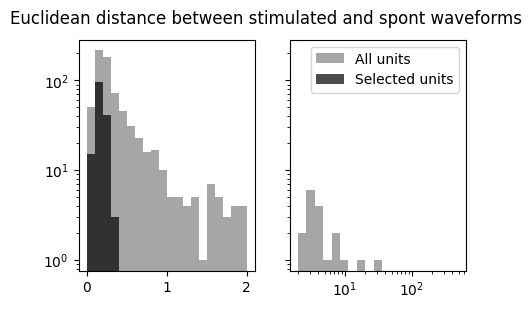

In [9]:
# plot euclidean distance histogram, with linear bins from 0 to boundary, and log bins larger than that
col = 'eu'
boundary = 2
tag_color = 'k'
nontag_color = 'gray'
edges_small = np.arange(0, boundary+0.1, 0.1)
edges_large = np.logspace(np.log10(boundary), np.log10(combined_tagged_units[col].max()), 20)
fig, axes = plt.subplots(1, 2, figsize=(5, 3), sharey=True)
ax = axes[0]
ax.hist(combined_tagged_units_good[col], bins=edges_small, color=nontag_color, alpha=0.7)
ax.hist(combined_tagged_units_filtered[col], bins=edges_small, color=tag_color, alpha=0.7)
ax.set_yscale('log')
ax = axes[1]
ax.hist(combined_tagged_units_good[col], bins=edges_large, color=nontag_color, alpha=0.7)
ax.hist(combined_tagged_units_filtered[col], bins=edges_large, color=tag_color, alpha=0.7)
ax.set_xscale('log')
ax.set_yscale('log')
plt.suptitle('Euclidean distance between stimulated and spont waveforms')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'euclidean_distance_histogram', ['FigureE10f_bottomleft'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'euclidean_distance_histogram', ['FigureE10f_bottomleft'])
###FigureE10f_bottomleft### dont't separate panels for histogram data save. Just one all good unit, one opto-tagged unit 

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_bottomright_correlation_histogram.csv']

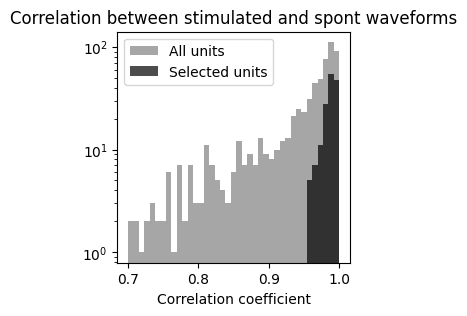

In [10]:
# plot euclidean distance histogram, with linear bins from 0 to boundary, and log bins larger than that
col = 'corr'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.linspace(0.7, 1, 40)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
plt.title('Correlation between stimulated and spont waveforms')
ax.set_xlabel('Correlation coefficient')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'correlation_histogram', ['FigureE10f_bottomright'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'correlation_histogram', ['FigureE10f_bottomright'])
###FigureE10f_bottomright###

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_topleft_ISI_histogram.csv']

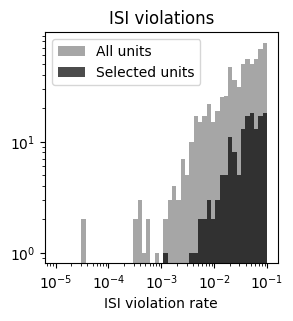

In [11]:
# plot ISI violation
col = 'isi_violations'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.logspace(np.log10(1e-5), np.log10(np.nanmax(combined_tagged_units_good[col])), 50)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
ax.set_xscale('log')
plt.title('ISI violations')
ax.set_xlabel('ISI violation rate')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'ISI_histogram', ['FigureE10f_topleft'], exts=('pdf',))

# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'ISI_histogram', ['FigureE10f_topleft'])
###FigureE10f_topleft### 

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_topright_peak_histogram.csv']

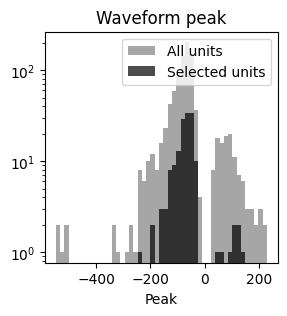

In [12]:
# plot waveform peak
col = 'peak'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.linspace(np.nanmin(combined_tagged_units_good[col]), np.nanmax(combined_tagged_units_good[col]), 50)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
plt.title('Waveform peak')
ax.set_xlabel('Peak')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'peak_histogram', ['FigureE10f_topright'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'peak_histogram', ['FigureE10f_topright'])
###FigureE10f_topright### 

In [16]:
combined_tagged_units_good.columns

Index(['session', 'unit_id', 'qc_pass', 'opto_tagged', 'in_df', 'trial_count',
       'p_max', 'p_mean', 'sig_counts', 'lat_max_p', 'isi_violations', 'snr',
       'amplitude_cutoff', 'presence_ratio', 'eu', 'corr', 'amp', 'amp_raw',
       'peak', 'peak_raw', 'wf', 'wf_raw', 'wf_aligned', 'wf_2d', 'wf_2d_raw',
       'probe', 'sex', 'y_loc', 'rec_side', 'top', 'bottom', 'in_LC',
       'tag_loc', 'fr', 'decoder', 'all_p_max', 'all_p_mean', 'all_lat_max_p',
       'all_corr', 'all_eu', 'all_sig_counts', 'x_ccf', 'y_ccf', 'z_ccf', 'sd',
       'rec_len', 'selected_qc_only', 'count_max', 'selected_opto_only',
       'selected', 'selected_no_opto'],
      dtype='object')

ValueError: setting an array element with a sequence.

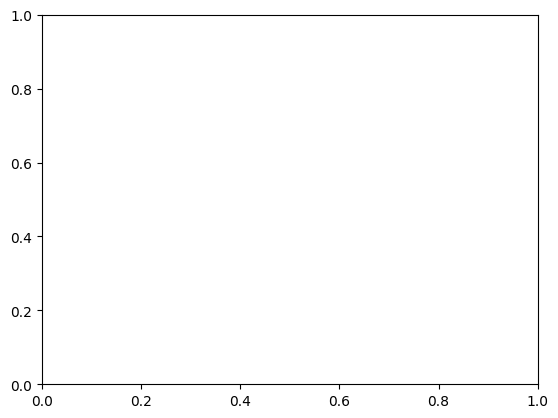

In [18]:
from scipy.stats import pearsonr, spearmanr

# p_response vs baseline
fig, ax = plt.subplots()
x_val = 'fr'
y_val = 'all_p_max'
colorcode = 'eu'

x = combined_tagged_units_good[x_val].values
y = combined_tagged_units_good[y_val].values
c = combined_tagged_units_good[colorcode].values

sc = ax.scatter(x, y, c=c, cmap='viridis', alpha=0.7)
plt.colorbar(sc, ax=ax, label=colorcode)

ax.set_xlabel('Firing Rate (Hz)')
ax.set_ylabel('Max P Response')
ax.set_title('P Response vs Firing Rate')

# correlation
mask = ~np.isnan(x) & ~np.isnan(y)
r_pearson, p_pearson = pearsonr(x[mask], y[mask])
r_spearman, p_spearman = spearmanr(x[mask], y[mask])
ax.text(0.05, 0.95,
        f'Pearson r={r_pearson:.2f} (p={p_pearson:.3f})\nSpearman ρ={r_spearman:.2f} (p={p_spearman:.3f})',
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()


## Load Behavioral Model Variables and Merge Feature Tables

Load outcome regression coefficients, response ratio table, and waveform features, then merge everything into a single `features_combined` DataFrame keyed on session and unit ID.

In [13]:
# load and add model variables
beh_folder = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'outcome_regressions')
model_combined = pd.read_csv(os.path.join(beh_folder, 'model_combined_beh_all.csv'), index_col=0)
model_combined['theta'] = model_combined['theta'] - 0.5
model_combined['unit_id'] = model_combined['unit_id'].apply(to_str_intlike)

versions = ['e', 'l', 'com']
for version in versions:
    all_vec = np.column_stack((
        model_combined[f'coef_outcome_{version}_mc'],
        model_combined[f'coef_Qchosen_{version}_ori']
    ))
    theta, rho = np.arctan2(all_vec[:, 1], all_vec[:, 0]), np.hypot(all_vec[:, 1], all_vec[:, 0])
    bound_1, bound_2, bound_3 = -(1 / 4) * np.pi, np.pi, -np.pi
    theta_scaled_dis = np.zeros_like(theta)
    for ind, angle_curr in enumerate(theta):
        if bound_1 < angle_curr <= bound_2:
            theta_scaled_dis[ind] = (angle_curr - bound_1) / (bound_2 - bound_1)
        else:
            theta_scaled_dis[ind] = (bound_1 - angle_curr) / (bound_1 - bound_3)
    theta_scaled_dis_all = 1 - theta_scaled_dis - 0.5
    model_combined[f'theta_{version}'] = theta_scaled_dis_all

# derived features
model_combined['coef_outcome|(|coef_outcome| + |coef_Q|)'] = (
    model_combined['coef_outcome_com_mc'] /
    (np.abs(model_combined['coef_outcome_com_mc']) + np.abs(model_combined['coef_Qchosen_com_mc']))
)
model_combined['outcome_ipsi'] = (
    model_combined['coef_outcome_com_mc'] + model_combined['coef_outcome:ipsi_com_mc']
)
model_combined['outcome_contra'] = (
    model_combined['coef_outcome_com_mc'] - model_combined['coef_outcome:ipsi_com_mc']
)

response_tbl = pd.read_csv(os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'response_regression', 'response_ratio_beh_all_go_cue.csv'))
response_tbl['unit_id'] = response_tbl['unit'].apply(to_str_intlike)


FileNotFoundError: [Errno 2] No such file or directory: '/root/capsule/scratch/result/manuscript/prep/outcome_regressions/model_combined_beh_all.csv'

In [ ]:
features_combined = basic_ephys_df.merge(combined_tagged_units_filtered[['session', 'unit_id', 'sex', 'x_ccf', 'y_ccf', 'z_ccf']], on=['session', 'unit_id'], how='inner')
features_combined = features_combined.merge(model_combined, on=['session', 'unit_id'], how='left')
features_combined = features_combined.merge(response_tbl, on=['session', 'unit_id'], how='left')

In [ ]:
# load waveforms and merge
waveform_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'waveforms_np', 'combined_features.csv')
wf_combined_features = pd.read_csv(waveform_file)
wf_combined_features.rename(columns={'unit': 'unit_id'}, inplace=True)
wf_combined_features['unit_id'] = wf_combined_features['unit_id'].apply(to_str_intlike)
features_combined = features_combined.merge(wf_combined_features, on=['session', 'unit_id'], how='left')
features_combined = features_combined.merge(fit_params_df, on=['session', 'unit_id'], how='left')

## Opto-Tagging Quality Scatter Plot

Plot a joint scatter of `p_max` vs. `sig_counts` with marginal histograms, comparing identified (opto-tagged) and unidentified units to illustrate the opto-tagging selection criteria.

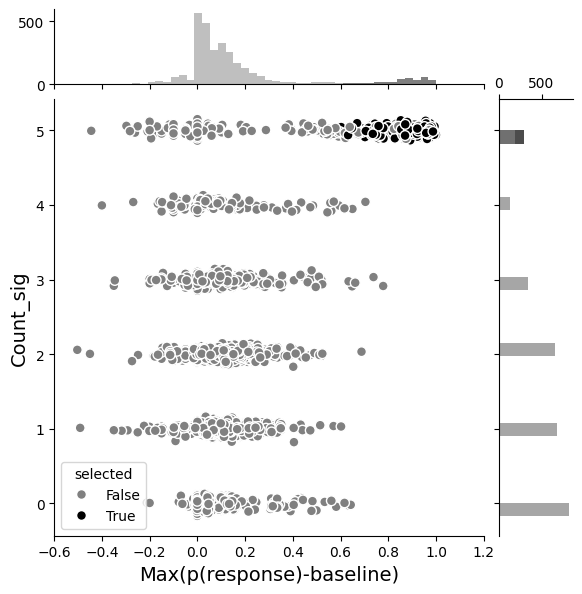

In [ ]:

# opto tagged vs not
# Define color palette for groups
palette = {True: "k", False: "gray"}
x_col = 'p_max'
y_col = 'sig_counts'

combined_tagged_units_plot = combined_tagged_units.copy()
combined_tagged_units_plot[y_col] = combined_tagged_units_plot[y_col]  + np.random.normal(0, 0.05, size=len(combined_tagged_units_plot[y_col]))  # add jitter to y-axis for better visibility

# Create JointGrid
g = sns.JointGrid(data=combined_tagged_units_plot[combined_tagged_units['selected_qc_only']], x=x_col, y=y_col, hue='selected', palette=palette)
g.plot_joint(
    sns.scatterplot,
    edgecolor='white',
    linewidth=1,
    alpha=1,
    s=50   # increase marker size if needed
)

# Add scatter plot in the center

g.ax_joint.set_xlim(-0.6, 1.2)

g.ax_joint.set_xlabel('Max(p(response)-baseline)', fontsize=14)
g.ax_joint.set_ylabel('Count_sig', fontsize=14)

# Add histograms manually for each group
p_max_bins = np.linspace(0, 1, 30)
y_bins = np.linspace(combined_tagged_units_plot[combined_tagged_units['selected_qc_only']][y_col].min(), combined_tagged_units[combined_tagged_units['selected_qc_only']][y_col].max(), 30)
x_bins = np.linspace(-0.6, 1, 50)
for qc_val, color in palette.items():
    subset = combined_tagged_units[combined_tagged_units['selected_qc_only'] & (combined_tagged_units['selected'] == qc_val)]
    # Horizontal histogram for x-axis (default orientation)
    ax = g.ax_marg_x
    ax.hist(subset[x_col], bins=x_bins, color=color, alpha=0.5, edgecolor='none')

    # **VERTICAL histogram for y-axis** using orientation="horizontal"
    ax = g.ax_marg_y
    ax.hist(subset[y_col], bins=y_bins, color=color, alpha=0.7, edgecolor='none',  orientation='horizontal')
g.ax_marg_y.set_axis_on()

g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(
    top=True,
    labeltop=True
)

g.ax_marg_x.set_axis_on()

g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(
    left=True,
    labelleft=True
)


save_panels(g.fig, target_folder, f'opto_pass_{x_col}_{y_col}_{criteria_name}', ['FigureE10e'], exts=('pdf', 'svg'), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter + marginal distributions share these columns) ----
_sub = combined_tagged_units[combined_tagged_units['selected_qc_only']]
save_panel_csv(columns_to_df(**{x_col: _sub[x_col].values, y_col: _sub[y_col].values, 'opto_tagged': _sub['selected'].values}), target_folder, f'opto_pass_{x_col}_{y_col}_{criteria_name}', ['FigureE10e'])
# Show plot
plt.show()

##FigureE10e##



## Go-Cue Excitation vs. Go-Baseline Correlation

Report dataset summary counts, then plot a joint scatter of baseline–response correlation (`bl_response_corr_short`) against normalized response rate for opto-tagged units, with Pearson r annotation.

In [ ]:
mask = features_combined['be_filter'].values
aniNames = [parseSessionID(session_curr)[0] for session_curr in features_combined[mask]['session']]
aniNames_F = [parseSessionID(session_curr)[0] for session_curr in features_combined[mask & (features_combined['sex']=='F')]['session']]
print(f"Animals count: {len(set(aniNames))}")
print(f"Animals count (F): {len(set(aniNames_F))}")
print(f"Session count: {len(features_combined[mask]['session'].unique())}")
print(f"Unit count: {len(features_combined[mask])}")

Animals count: 21
Animals count (F): 4
Session count: 123
Unit count: 274


In [ ]:
features_combined['response_increase'] = features_combined['response_fr'] - features_combined['bl_mean']
features_combined['response_rate_mean'] = (features_combined['response_fr'] - features_combined['bl_mean'])/features_combined['bl_mean']

['/root/capsule/scratch/results/manuscript/figures/F_basic_ephys/Figure4h_joint_plot_bl_response_corr_short_response_rate_mean_basic_ephys_all.csv']

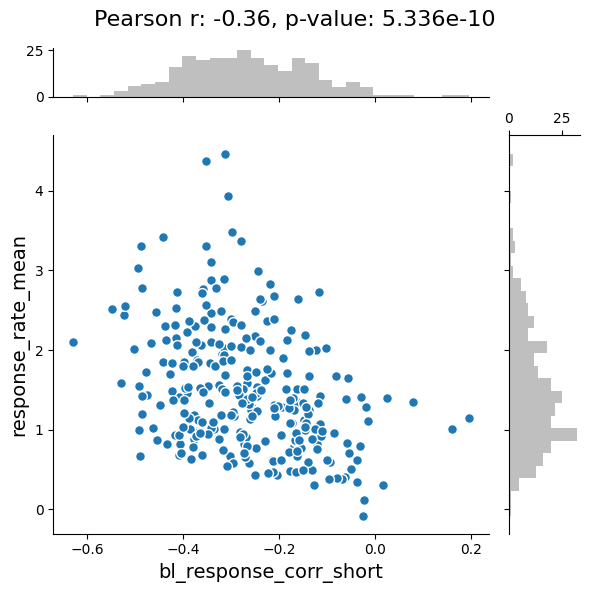

In [ ]:
# joint plot between x and y
x_val = 'bl_response_corr_short'
y_val = 'response_rate_mean'
mask = features_combined['be_filter'].values
# Create JointGrid
g = sns.JointGrid(data=features_combined[mask], x=x_val, y=y_val)
g.plot_joint(sns.scatterplot, alpha=1, edgecolor='white', linewidth=1, s=50)
g.ax_joint.set_xlabel(x_val, fontsize=14)
g.ax_joint.set_ylabel(y_val, fontsize=14)
# Add histograms for x and y axes
x_bins = np.linspace(features_combined[mask][x_val].min(), features_combined[mask][x_val].max(), 30)
y_bins = np.linspace(features_combined[mask][y_val].min(), features_combined[mask][y_val].max(), 30)
g.ax_marg_x.hist(features_combined[mask][x_val], bins=x_bins, color='gray', alpha=0.5, edgecolor='none')
g.ax_marg_y.hist(features_combined[mask][y_val], bins=y_bins, color='gray', alpha=0.5, edgecolor='none', orientation='horizontal')
g.ax_marg_y.set_axis_on()
g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(
    top=True,
    labeltop=True
)
g.ax_marg_x.set_axis_on()
g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(
    left=True,
    labelleft=True
)

# compute correlation and add to title
corr_coef, p_value = pearsonr(features_combined[mask][x_val], features_combined[mask][y_val])
g.fig.suptitle(f'Pearson r: {corr_coef:.2f}, p-value: {p_value:.3e}', fontsize=16)
plt.tight_layout()
save_panels(g.fig, target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'], exts=('svg',), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter) ----
_m = features_combined['be_filter'].values
save_panel_csv(columns_to_df(**{x_val: features_combined[x_val][_m].values, y_val: features_combined[y_val][_m].values}), target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'])

##Figure4h##